# 8. Small maps, ranked evidence

**Question:** Can a reader compare estimates while retaining geographic context?
**Objectives:** link ranked summaries to location, show uncertainty, and build an original border
group for `micromapST`. **Time:** 45 minutes. **Prerequisites:** Chapters 2 and 3.

Twelve fictional districts have binomial outcomes generated independently given different
probabilities. Each outcome has a denominator. Wilson 95% intervals express sampling uncertainty
under that illustrative binomial model; they do not quantify measurement error or spatial dependence.
No packaged boundary data is used. The optional extension creates its own square geography.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=08-linked-micromaps.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 08 | Original micromap teaching data.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: simulated trials | Outputs: rank plot, custom border group.
# Dependencies: base R; optional sf and micromapST. Change log: initial lesson.
set.seed(20261116)
district <- expand.grid(x = 0:3, y = 0:2)
district$id <- sprintf("D%02d", 1:12)
district$n <- sample(200:1500, 12)
district$events <- rbinom(12, district$n, .10 + .025 * district$x)
p <- district$events / district$n
q <- qnorm(.975)
center <- (p + q^2 / (2 * district$n)) / (1 + q^2 / district$n)
half <- q * sqrt(p * (1-p) / district$n + q^2 / (4 * district$n^2)) / (1 + q^2 / district$n)
district$percent <- 100 * p
district$lower <- 100 * (center - half)
district$upper <- 100 * (center + half)
stopifnot(all(district$lower >= 0), all(district$upper <= 100),
          all(district$lower <= district$percent), all(district$upper >= district$percent))
ranked <- district[order(district$percent), ]
print(ranked[c("id", "n", "events", "percent", "lower", "upper")], row.names = FALSE)

  id    n events   percent     lower    upper
 D01 1265    113  8.932806  7.482873 10.63140
 D10  638     59  9.247649  7.237131 11.74598
 D05  711     72 10.126582  8.118983 12.56273
 D09 1225    128 10.448980  8.857856 12.28738
 D06  510     60 11.764706  9.250155 14.85095
 D04  562     75 13.345196 10.781070 16.40702
 D07  337     46 13.649852 10.391837 17.72724
 D02  471     65 13.800425 10.977267 17.20929
 D03 1453    206 14.177564 12.478337 16.06571
 D11 1220    177 14.508197 12.643333 16.59587
 D08 1341    239 17.822521 15.866992 19.96188
 D12 1311    270 20.594966 18.493360 22.86839


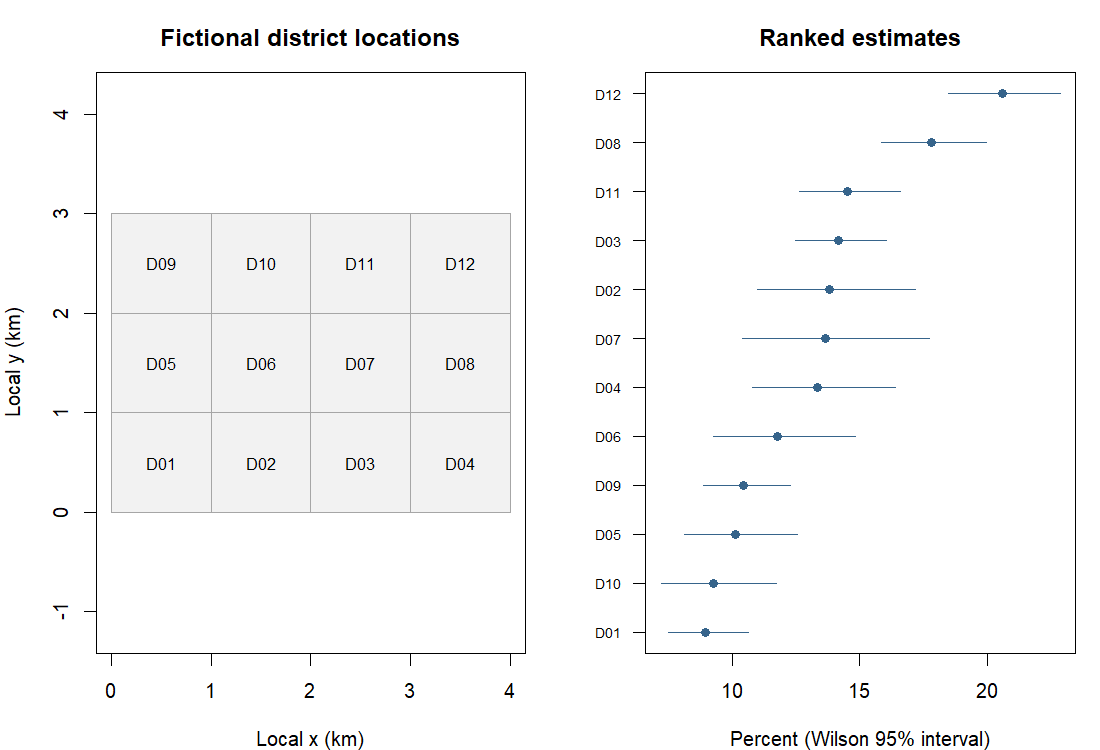

In [2]:
par(mfrow = c(1,2), mar = c(4,4,3,1))
plot(district$x+.5, district$y+.5, type = "n", asp = 1, xlim = c(0,4), ylim = c(0,3),
     xlab = "Local x (km)", ylab = "Local y (km)", main = "Fictional district locations")
rect(district$x, district$y, district$x+1, district$y+1, col = "grey95", border = "grey65")
text(district$x+.5, district$y+.5, district$id, cex = .8)
plot(ranked$percent, 1:12, xlim = range(c(ranked$lower,ranked$upper)), pch = 19,
     col = "steelblue4", yaxt = "n", xlab = "Percent (Wilson 95% interval)", ylab = "",
     main = "Ranked estimates")
axis(2, at = 1:12, labels = ranked$id, las = 1, cex.axis = .7)
segments(ranked$lower, 1:12, ranked$upper, 1:12, col = "steelblue4")
par(mfrow = c(1,1))

## Extension: actual linked micromaps
Install `micromapST` deliberately with `webr::install("micromapST")`. It has a substantial
dependency tree. In Lab the example reads a small prebuilt border group from `data/FictionalBG.rda`.
It was generated from the exact original polygons below in desktop R. This avoids a browser
failure in the V8-backed border-construction dependency; rendering is tested separately.
The package groups ranked districts and links map highlights to statistical panels. Building a
custom border group in desktop R writes intermediate files to a temporary folder. The square polygons and
name table below are our own; we do not reproduce the package's bundled geographic datasets.

In [ ]:
if (requireNamespace("sf", quietly = TRUE) && requireNamespace("micromapST", quietly = TRUE)) {
  if (grepl("emscripten", R.version$platform, fixed = TRUE)) {
    border_dir <- "data"
    stopifnot(file.exists(file.path(border_dir, "FictionalBG.rda")))
  } else {
  polygons <- lapply(seq_len(nrow(district)), function(i) {
    x <- 500000 + district$x[i] * 1000; y <- 4400000 + district$y[i] * 1000
    sf::st_polygon(list(rbind(c(x,y), c(x+1000,y), c(x+1000,y+1000), c(x,y+1000), c(x,y))))
  })
  shapes <- sf::st_sf(link = district$id, geometry = sf::st_sfc(polygons, crs = 32618))
  names_table <- data.frame(Link = district$id, Name = paste("District", district$id),
                            Abbr = district$id, ID = sprintf("%02d", 1:12))
  border_dir <- tempfile("original-border-")
  dir.create(border_dir)
  micromapST::BuildBorderGroup(ShapeFile = shapes, ShapeLinkName = "link",
    NameTableFile = names_table, NameTableLink = "Link", NameTableDir = border_dir,
    BorderGroupName = "FictionalBG", BorderGroupDir = border_dir, ReducePC = 99,
    MapHdr = c("", "Fictional areas"), IDHdr = c("", "District"))
  }
  panel <- data.frame(type = c("map", "id", "dotconf"),
    lab1 = c("Location", "District", "Simulated percent"),
    lab2 = c("", "", "Wilson 95% interval"),
    col1 = c(NA, NA, "percent"), col2 = c(NA, NA, "lower"), col3 = c(NA, NA, "upper"))
  micromapST::micromapST(district, panel, rowNamesCol = "id", rowNames = "ab",
    sortVar = "percent", ascend = TRUE, bordGrp = "FictionalBG", bordDir = border_dir,
    title = c("Original synthetic districts", "Linked estimates and geographic context"))
} else message("Optional micromapST extension skipped: sf and micromapST are required. Core rank/interval lesson is complete.")

## Practice and check
1. Increase one district's denominator while keeping its proportion approximately constant.
2. Sort by denominator rather than estimate. What changes in the visual narrative?
3. Explain why overlapping 95% intervals are not a general pairwise significance test.
**Checkpoint:** all intervals remain within 0–100%; the name table has exactly one unique key
per polygon. Ranking point estimates does not make that ordering certain.

## Sources and attribution
[micromapST reference manual](https://jpearson0525.r-universe.dev/micromapST/doc/manual.html);
[Pickle, Pearson and Carr (2015), JSS 63(3)](https://doi.org/10.18637/jss.v063.i03);
[Wilson (1927)](https://doi.org/10.1080/01621459.1927.10502953).
We cite these methods; no publication figure, prose, dataset, or boundary is reproduced.